# LightGBM with SHAP - subsurface_Layer03



In [ ]:
# Imports and Configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import pickle, json, time, warnings
warnings.filterwarnings('ignore')
from google.colab import drive
from sklearn.metrics import classification_report, confusion_matrix

import xarray as xr
import math
import lightgbm as lgb
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, roc_auc_score, average_precision_score
import shap
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

SEED = 42
np.random.seed(SEED)

# Configuration
CONFIG_NAME = 'subsurface_layer_100-150m_layer'
FEATURES = ['sst', 'wind_speed','ssr_flux', 'str_flux', 'latent_flux', 'sensible_flux', 't2m', 'msl','temp_0_50m', 'temp_50_100m', 'temp_100_150m']
TARGET = 'mhw_layer3'
LEAD_TIMES = [3, 5, 7, 9, 12, 14]
N_LAGS = 14


LGBM_PARAMS = {
    'objective': 'binary',
    # 'metric': ['auc', 'binary_logloss', 'average_precision'],
    'boosting_type': 'gbdt',

    'num_leaves': 63,
    'max_depth': 6,
    'min_child_samples': 500,

    # Slower learning + more rounds
    'learning_rate': 0.05,
    'n_estimators': 3500,

    # Regularisation — critical for distribution shift
    'reg_alpha': 0.1,          # L1 —
    'reg_lambda': 1.0,         # L2 —
    'min_gain_to_split': 0.01, # prevent trivial splits

    # Sampling
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'subsample_freq': 1,       # enables subsample every round
    'scale_pos_weight': 9.3,   # neg/pos from training set
    # 'class_weight': 'balanced',
    'random_state': SEED,
    'verbose': -1, # prevent showin the progress bar in logs
    'n_jobs': -1, #parallel process to use all core available
}


def lgb_f1_score(y_true, y_pred):
    """F1 Score - most important for imbalanced data."""
    y_pred_binary = (y_pred > 0.5).astype(int)
    score = f1_score(y_true, y_pred_binary, zero_division=0)
    return 'f1', score, True

def lgb_precision(y_true, y_pred):
    """Precision - how many predicted MHWs are actually MHWs."""
    y_pred_binary = (y_pred > 0.5).astype(int)
    score = precision_score(y_true, y_pred_binary, zero_division=0)
    return 'precision', score, True

def lgb_recall(y_true, y_pred):
    """Recall - how many actual MHWs catch."""
    y_pred_binary = (y_pred > 0.5).astype(int)
    score = recall_score(y_true, y_pred_binary, zero_division=0)
    return 'recall', score, True

print('='*80)
print(f'LightGBM with SHAP: {CONFIG_NAME}')
print('='*80)

LightGBM with SHAP: subsurface_layer_100-150m_layer


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Output directory
OUTPUT_DIR = Path('/content/drive/MyDrive/MSc-research-code/trained_models/lightbgm_subsurface_layer_100-150m_layer')
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)


In [ ]:
# Load Data


def xr_to_df(ds, features, targets):
    """Convert xarray Dataset to pandas DataFrame."""
    print('Converting xarray → pandas...')
    stacked = ds[features + targets].stack(sample=('time', 'latitude', 'longitude'))
    df = stacked.to_dataframe().reset_index()

    initial_len = len(df)
    df = df.dropna(subset=['sst'])
    print(f'  Removed {initial_len - len(df):,} land points')

    df = df.sort_values(['latitude', 'longitude', 'time']).reset_index(drop=True)
    df['location'] = df['latitude'].astype(str) + '_' + df['longitude'].astype(str)

    for col in features:
        if col in df.columns:
            df[col] = df[col].astype(np.float32)
    for col in targets:
        if col in df.columns:
            df[col] = df[col].astype(np.int8)

    print(f'  Samples: {len(df):,}')
    return df


In [ ]:
NETCDF_FILE = '/content/drive/MyDrive/MSc-research-code/data/ocean_atmos_DAILY_WITH_LABELS_1993_2025.nc'

print('Loading NetCDF...')
ds = xr.open_dataset(NETCDF_FILE)
df = xr_to_df(ds, FEATURES, [TARGET])
ds.close()

print(f'Data loaded: {df.shape}')
print('='*80)

Loading NetCDF...
Converting xarray → pandas...
  Removed 3,061,462 land points
  Samples: 11,703,463
Data loaded: (11703463, 18)


In [ ]:

# TRAIN_END_DATE = '2019-12-31'
# TEST_START_DATE = '2020-01-15'

# df['time'] = pd.to_datetime(df['time'])
# train_df = df[df['time'] <= TRAIN_END_DATE].copy()
# test_df = df[df['time'] >= TEST_START_DATE].copy()

# print(f'Train: {len(train_df):,} samples')
# print(f'Test:  {len(test_df):,} samples')

# # del df
# # import gc; gc.collect()
# # print('='*80)

In [ ]:
TRAIN_END_DATE = '2019-12-31'
VAL_START_DATE = '2020-01-15'
VAL_END_DATE = '2022-12-31'
TEST_START_DATE = '2023-01-15'

df['time'] = pd.to_datetime(df['time'])
train_df = df[df['time'] <= TRAIN_END_DATE].copy()
val_df = df[(df['time'] >= VAL_START_DATE) & (df['time'] <= VAL_END_DATE)].copy()
test_df = df[df['time'] >= TEST_START_DATE].copy()

print(f'Train: {len(train_df):,} samples')
print(f'Validation: {len(val_df):,} samples')
print(f'Test:  {len(test_df):,} samples')

del df
import gc; gc.collect()
print('='*80)

Train: 9,575,031 samples
Validation: 1,050,622 samples
Test:  1,050,622 samples


In [ ]:
#  MHW Summary
print('\nMHW Event Summary')
print('='*60)
print(f"{'Split':<8} {'Period':<15} {'Days':>10} {'MHW Days':>10} {'Rate':>7}")
print('-'*60)

for name, df_split, start, end in [
    ('Train', train_df, '1993-01-01', TRAIN_END_DATE),
    ('Val',   val_df,   VAL_START_DATE, VAL_END_DATE),
    ('Test',  test_df,  TEST_START_DATE, '2025-12-31'),
]:
    total  = len(df_split)
    mhw    = int(df_split[TARGET].sum())  # ← your MHW column name
    rate   = mhw / total * 100
    print(f"{name:<8} {start+' – '+end:<15} {total:>10,} {mhw:>10,} {rate:>6.1f}%")

print('='*60)


MHW Event Summary
Split    Period                Days   MHW Days    Rate
------------------------------------------------------------
Train    1993-01-01 – 2019-12-31  9,575,031    974,849   10.2%
Val      2020-01-15 – 2022-12-31  1,050,622    146,397   13.9%
Test     2023-01-15 – 2025-12-31  1,050,622    448,422   42.7%


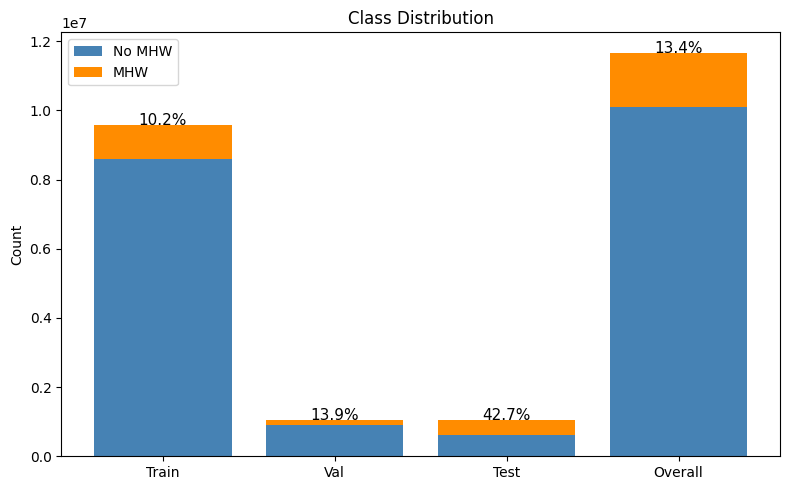

In [ ]:
# Counts
splits = ['Train', 'Val', 'Test', 'Overall']
dfs = [train_df, val_df, test_df, pd.concat([train_df, val_df, test_df])]

non_mhw = [df[TARGET].value_counts()[0] for df in dfs]
mhw     = [df[TARGET].value_counts()[1] for df in dfs]

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
x = range(len(splits))

ax.bar(x, non_mhw, label='No MHW', color='steelblue')
ax.bar(x, mhw, bottom=non_mhw, label='MHW', color='darkorange')

for i in x:
    rate = mhw[i] / (mhw[i] + non_mhw[i]) * 100
    ax.text(i, mhw[i] + non_mhw[i], f'{rate:.1f}%', ha='center', fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.set_ylabel('Count')
ax.legend()
ax.set_title('Class Distribution')
plt.tight_layout()
plt.show()

In [ ]:

def create_multi_output_targets(df, target_col, lead_times):
    """
    Create multi-output targets for a specific MHW variable.

    Citation: Ben Taieb & Atiya (2016) DOI: 10.1109/TNNLS.2015.2411629
    """
    df = df.copy().sort_values(['location', 'time']).reset_index(drop=True)

    target_cols = []
    for lead in lead_times:
        col_name = f'{target_col}_lead{lead}'
        # Shift target FORWARD by lead days (negative shift)
        df[col_name] = df.groupby('location', sort=False)[target_col].shift(-lead)
        target_cols.append(col_name)

    # Remove rows with NaN in any target
    initial_len = len(df)
    df = df.dropna(subset=target_cols)
    dropped = initial_len - len(df)

    print(f'  Target: {target_col:15s} | Created: {len(target_cols)} | '
          f'Samples: {len(df):,} (dropped {dropped:,})')

    return df, target_cols

# Create targets for EACH configuration
print('Creating Multi-Output Targets')
print('='*80)

train_targets = {}  # {config_name: (dataframe, target_cols)}
test_targets = {}

# for config_name, config_dict in DEPTH_CONFIGS.items():
#     target = config_dict['target']
#     print(f'\n{config_name}:')

# Train
train_df_config, train_cols = create_multi_output_targets(
  train_df, TARGET, LEAD_TIMES
)
train_targets = (train_df_config, train_cols)

# Val
val_df_config, val_cols = create_multi_output_targets(
  val_df, TARGET, LEAD_TIMES
)
val_targets = (val_df_config, val_cols)

# Test
test_df_config, test_cols = create_multi_output_targets(
  test_df, TARGET, LEAD_TIMES
)
test_targets = (test_df_config, test_cols)

print('\n' + '='*80)
print('All multi-output targets created')
print('='*80)

Creating Multi-Output Targets
  Target: mhw_layer3      | Created: 6 | Samples: 9,561,437 (dropped 13,594)
  Target: mhw_layer3      | Created: 6 | Samples: 1,037,028 (dropped 13,594)
  Target: mhw_layer3      | Created: 6 | Samples: 1,037,028 (dropped 13,594)

All multi-output targets created


In [ ]:
def create_lag_features(df, features, n_lags=14):
    """
    Create lag features for gradient boosting models.

    Creates: feature_lag1, feature_lag2, ..., feature_lag14
    """
    df = df.copy().sort_values(['location', 'time']).reset_index(drop=True)

    lag_cols = []
    for feat in features:
        for lag in range(0, n_lags + 1):
            col_name = f'{feat}_lag{lag}'
            # Shift DOWN (into past)
            df[col_name] = df.groupby('location', sort=False)[feat].shift(lag)
            lag_cols.append(col_name)

    # Remove rows with NaN from lagging
    # df = df.dropna(subset=lag_cols)
    all_nan_mask = df[lag_cols].isna().all(axis=1)
    df = df[~all_nan_mask]
    print(f'  Dropped {all_nan_mask.sum():,} all-NaN startup rows')

    print(f'  Features: {len(features)} | Lags: {n_lags} | '
          f'Total lag cols: {len(lag_cols)} | Samples: {len(df):,}')

    return df, lag_cols



lgbm_train_data = {}  # {config_name: (dataframe, lag_cols)}
lgbm_val_data = {}
lgbm_test_data = {}

# for config_name, config_dict in DEPTH_CONFIGS.items():
#     features = config_dict['features']
#     print(f'\n{config_name}:')

# Get data with targets already created
train_df_config, _ = train_targets
val_df_config, _ = val_targets
test_df_config, _ = test_targets

# Create lags
train_lagged, train_lag_cols = create_lag_features(train_df_config, FEATURES, n_lags=14)
lgbm_train_data = (train_lagged, train_lag_cols)

val_lagged, val_lag_cols = create_lag_features(val_df_config, FEATURES, n_lags=14)
lgbm_val_data = (val_lagged, val_lag_cols)

test_lagged, test_lag_cols = create_lag_features(test_df_config, FEATURES, n_lags=14)
lgbm_test_data = (test_lagged, test_lag_cols)

print('\n' + '='*80)
print('Lag features created')
print('='*80)

  Dropped 0 all-NaN startup rows
  Features: 11 | Lags: 14 | Total lag cols: 165 | Samples: 9,561,437
  Dropped 0 all-NaN startup rows
  Features: 11 | Lags: 14 | Total lag cols: 165 | Samples: 1,037,028
  Dropped 0 all-NaN startup rows
  Features: 11 | Lags: 14 | Total lag cols: 165 | Samples: 1,037,028

Lag features created


In [ ]:
def sedi(tp, fp, fn, tn):
    """
    Symmetric Extremal Dependence Index.
    Community standard metric for rare MHW events.
    SEDI = 0 → no skill above random
    SEDI = 1 → perfect forecast
    """
    H = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    F = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    eps = 1e-7
    H = np.clip(H, eps, 1 - eps)
    F = np.clip(F, eps, 1 - eps)

    return float(
        (np.log(F) - np.log(H) -
         np.log(1-F) + np.log(1-H))
        /
        (np.log(F) + np.log(H) +
         np.log(1-F) + np.log(1-H))
    )


def bss(y_true, y_prob, climatology_rate=None):
    """
    Brier Skill Score vs climatology.
    BSS > 0 → better than climatology
    BSS = 0 → same as climatology
    BSS < 0 → worse than climatology
    BSS = nan → undefined (all same class)
    """
    bs_model = np.mean((y_prob - y_true) ** 2)

    if climatology_rate is None:
        climatology_rate = y_true.mean()

    bs_clim = np.mean((climatology_rate - y_true) ** 2)

    if bs_clim == 0:
        return np.nan    # undefined — all same class

    return float(1 - bs_model / bs_clim)

In [ ]:
def compute_metrics(y_test, y_pred, y_prob, threshold,
                    strategy, model_name, config, target, lead):
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        'model': model_name,
        'config': config,
        'target': target,
        'lead_time': lead,
        'threshold_strategy': strategy,
        'best_threshold': float(threshold),
        'auc': roc_auc_score(y_test, y_prob),
        'avg_precision': average_precision_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'f1_0': f1_score(y_test, y_pred, pos_label=0, zero_division=0),
        'precision_0': precision_score(y_test, y_pred, pos_label=0, zero_division=0),
        'recall_0': recall_score(y_test, y_pred, pos_label=0, zero_division=0),
        'accuracy': accuracy_score(y_test, y_pred),
        'macro_f1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'tn': int(tn), 'fp': int(fp),
        'fn': int(fn), 'tp': int(tp),
        'tpr': float(tp / (tp + fn)),
        'tnr': float(tn / (tn + fp)),
        'fpr': float(fp / (fp + tn)),
        'csi': float(tp / (tp + fp + fn)),
        'sedi': sedi(tp, fp, fn, tn),
        'bss':  bss(y_test, y_prob),
        'mhw_rate_test': float(y_test.mean())
    }

In [ ]:
# Train Models (NO SCALING!)

models = {}
results = []

print('Training LightGBM Models')
print('='*80)

for lead in LEAD_TIMES:
    print(f'\n>>> Lead {lead}d')
    print('-'*80)



    start = time.time()

    train_df_lead, lag_cols = lgbm_train_data
    val_df_lead, _ = lgbm_val_data
    test_df_lead, _ = lgbm_test_data


    # NO SCALING for LightGBM!
    X_train = train_df_lead[lag_cols].values.astype(np.float32)
    y_train = train_df_lead[f'{TARGET}_lead{lead}'].values.astype(np.int8)

    X_val = val_df_lead[lag_cols].values.astype(np.float32)
    y_val = val_df_lead[f'{TARGET}_lead{lead}'].values.astype(np.int8)

    X_test = test_df_lead[lag_cols].values.astype(np.float32)
    y_test = test_df_lead[f'{TARGET}_lead{lead}'].values.astype(np.int8)

    neg = np.sum(y_train == 0)
    pos = np.sum(y_train == 1)
    spw = math.sqrt(neg / pos)

    params = LGBM_PARAMS.copy()
    params['scale_pos_weight'] = spw

    # Sanity check print
    print(f"  Class distribution - Train: [{neg}  {pos}]")
    print(f"  MHW rate - Train: {pos/(neg+pos)*100:.1f}%")
    print(f"  scale_pos_weight: {spw:.2f}")

    # extracting X_train, y_train:
    # print(f'  Class distribution - Train: {np.bincount(y_train)}')
    print(f'  Class distribution - Validation: {np.bincount(y_val)}')
    print(f'  Class distribution - Test: {np.bincount(y_test)}')
    print(f'  MHW rate - Train: {y_train.mean()*100:.1f}%')
    print(f'  MHW rate - Validation: {y_val.mean()*100:.1f}%')
    print(f'  MHW rate - Test: {y_test.mean()*100:.1f}%')

    print(f'X_train: {X_train.shape} | X_test: {X_test.shape}')

    # # Train
    model = lgb.LGBMClassifier(**params)

    model.fit(
        X_train, y_train,
        eval_set=[(X_train, y_train), (X_val, y_val)],
        eval_names=['train', 'valid'],
        eval_metric=[ 'auc'],
        callbacks=[
            lgb.early_stopping(50, first_metric_only=True, verbose=True),
            lgb.log_evaluation(10)
        ]
    )
    # Evaluate
    # Threshold tuning on validation set
    # y_val_prob = model.predict_proba(X_val)[:, 1]

    # thresholds = np.arange(0.1, 0.9, 0.01)
    # f1_scores = [f1_score(y_val, (y_val_prob > t).astype(int))
    #             for t in thresholds]
    # best_threshold = thresholds[np.argmax(f1_scores)]

    # print(f"  Best threshold (val): {best_threshold:.2f}")
    # print(f"  Best val F1: {max(f1_scores):.3f}")

    # # Apply best threshold to test
    # y_prob = model.predict_proba(X_test)[:, 1]
    # y_pred = (y_prob > best_threshold).astype(int)

    y_val_prob = model.predict_proba(X_val)[:, 1]
    thresholds = np.arange(0.1, 0.9, 0.01)



    # ----------------------------------------------------------
    # Calibration
    # ----------------------------------------------------------
    print('\n  Calibrating...')

    calibrator = IsotonicRegression(out_of_bounds='clip')
    calibrator.fit(y_val_prob, y_val)

    cal_val_prob  = calibrator.transform(y_val_prob)
    # APPLY BOTH THRESHOLDS TO TEST SET
    y_test_prob        = model.predict_proba(X_test)[:, 1]
    cal_test_prob = calibrator.transform(y_test_prob)

    # Brier score — measures calibration quality
    # Lower = better calibration
    brier_raw = brier_score_loss(y_test, y_test_prob)
    brier_cal = brier_score_loss(y_test, cal_test_prob)

    actual_rate = y_val.mean()
    print(f'  Val MHW rate:          {actual_rate*100:.1f}%')
    print(f'  Mean raw probability:  {y_val_prob.mean()*100:.1f}%')
    print(f'  Mean cal probability:  {cal_val_prob.mean()*100:.1f}%')
    print(f'  Calibration works?     '
          f'{"Yes" if abs(cal_val_prob.mean()-actual_rate) < abs(y_val_prob.mean()-actual_rate) else "Warning -Check"}')
    print(f'  Brier raw:             {brier_raw:.4f}')
    print(f'  Brier calibrated:      {brier_cal:.4f}')
    print(f'  Brier improvement?     '
          f'{"Yes" if brier_cal < brier_raw else " Warning - Check"}')

    # Strategy 1 — MHW class F1 (detection focused)
    f1_mhw_scores = [
        f1_score(y_val, (cal_val_prob > t).astype(int),
                zero_division=0)
        for t in thresholds
    ]
    best_threshold_mhw = thresholds[np.argmax(f1_mhw_scores)]

    # Strategy 2 — Macro F1 (balanced)
    f1_macro_scores = [
        f1_score(y_val, (cal_val_prob > t).astype(int),
                average='macro', zero_division=0)
        for t in thresholds
    ]
    best_threshold_macro = thresholds[np.argmax(f1_macro_scores)]

    print(f"  Threshold (MHW F1):   {best_threshold_mhw:.2f} "f"| Val F1: {max(f1_mhw_scores):.3f}")
    print(f"  Threshold (Macro F1): {best_threshold_macro:.2f} "f"| Val Macro F1: {max(f1_macro_scores):.3f}")


    # # APPLY BOTH THRESHOLDS TO TEST SET
    # y_prob = model.predict_proba(X_test)[:, 1]

    y_pred_mhw   = (cal_test_prob > best_threshold_mhw).astype(int)
    y_pred_macro = (cal_test_prob > best_threshold_macro).astype(int)

    # CONFUSION MATRICES FOR BOTH
    cm_mhw   = confusion_matrix(y_test, y_pred_mhw)
    cm_macro = confusion_matrix(y_test, y_pred_macro)

    tn_m, fp_m, fn_m, tp_m = cm_mhw.ravel()
    tn_b, fp_b, fn_b, tp_b = cm_macro.ravel()


    result_mhw = compute_metrics( y_test, y_pred_mhw, cal_test_prob, best_threshold_mhw, 'mhw_f1','LightGBM', CONFIG_NAME, TARGET, lead)

    result_macro = compute_metrics(y_test, y_pred_macro, cal_test_prob, best_threshold_macro, 'macro_f1','LightGBM', CONFIG_NAME, TARGET, lead)

    # Add brier and calibration flag to results
    for r in [result_mhw, result_macro]:
      r['brier_raw']        = float(brier_raw)
      r['brier_calibrated'] = float(brier_cal)
      r['calibrated']       = True

    # Per-class metrics
    print('=== MHW F1 THRESHOLD (Detection Focused) ===')
    print(classification_report(
        y_test, y_pred_mhw,
        target_names=['No MHW (0)', 'MHW (1)'],
        digits=3
    ))
    print(f'    TN={tn_m:,} | FP={fp_m:,}')
    print(f'    FN={fn_m:,} | TP={tp_m:,}')
    print(f'    TPR={result_mhw["tpr"]:.3f} | TNR={result_mhw["tnr"]:.3f}')
    print(f'    FPR={result_mhw["fpr"]:.3f} | CSI={result_mhw["csi"]:.3f}')

    print('\n=== MACRO F1 THRESHOLD (Balanced) ===')
    print(classification_report(
        y_test, y_pred_macro,
        target_names=['No MHW (0)', 'MHW (1)'],
        digits=3
    ))
    print(f'    TN={tn_b:,} | FP={fp_b:,}')
    print(f'    FN={fn_b:,} | TP={tp_b:,}')
    print(f'    TPR={result_macro["tpr"]:.3f} | TNR={result_macro["tnr"]:.3f}')
    print(f'    FPR={result_macro["fpr"]:.3f} | CSI={result_macro["csi"]:.3f}')

    results.append(result_mhw)
    results.append(result_macro)
    models[lead] = model

    elapsed = time.time() - start

    # Final summary line
    print(f'\nMHW F1:   F1={result_mhw["f1"]:.3f} '
          f'AUC={result_mhw["auc"]:.3f} '
          f'FPR={result_mhw["fpr"]:.3f} '
          f'TPR={result_mhw["tpr"]:.3f}')

    print(f'Macro F1: F1={result_macro["f1"]:.3f} '
          f'AUC={result_macro["auc"]:.3f} '
          f'FPR={result_macro["fpr"]:.3f} '
          f'TPR={result_macro["tpr"]:.3f}')

    print(f'Brier:    raw={brier_raw:.4f} → '
      f'cal={brier_cal:.4f} '
      f'{"okay" if brier_cal < brier_raw else "warning"}')
    print(f'SEDI:     {result_mhw["sedi"]:.3f} | '
      f'BSS: {result_mhw["bss"]:.3f}')

    # Save model
    model_path = OUTPUT_DIR / f'lgbm_{CONFIG_NAME}_lead{lead}.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model, f)
    print(f'Saved: {model_path.name}')

    with open(OUTPUT_DIR / f'lgbm_{CONFIG_NAME}_lead{lead}_calibrator.pkl', 'wb') as f:
        pickle.dump(calibrator, f)
    # History

print('\nAll models trained')
print('='*80)

Training LightGBM Models

>>> Lead 3d
--------------------------------------------------------------------------------
  Class distribution - Train: [8587414  974023]
  MHW rate - Train: 10.2%
  scale_pos_weight: 2.97
  Class distribution - Validation: [891178 145850]
  Class distribution - Test: [593469 443559]
  MHW rate - Train: 10.2%
  MHW rate - Validation: 14.1%
  MHW rate - Test: 42.8%
X_train: (9561437, 165) | X_test: (1037028, 165)
Training until validation scores don't improve for 50 rounds
[10]	train's auc: 0.879076	train's binary_logloss: 0.264045	valid's auc: 0.809855	valid's binary_logloss: 0.340709
[20]	train's auc: 0.882652	train's binary_logloss: 0.254758	valid's auc: 0.814341	valid's binary_logloss: 0.32879
[30]	train's auc: 0.884946	train's binary_logloss: 0.253859	valid's auc: 0.817207	valid's binary_logloss: 0.326819
[40]	train's auc: 0.88747	train's binary_logloss: 0.25446	valid's auc: 0.820716	valid's binary_logloss: 0.326753
[50]	train's auc: 0.889497	train's bi

In [ ]:
# SHAP Feature Importance

print('SHAP Feature Importance Analysis')
print('='*80)
print('Computing SHAP values (this may take a few minutes)...')

shap_data = {}
importance_data = []

for lead in LEAD_TIMES:
    print(f'\n>>> Lead {lead}d')
    print('-'*80)

    model = models[lead]
    test_df_lead, lag_cols = lgbm_test_data

    # Sample data for SHAP (use subset for speed)
    X_sample = test_df_lead[lag_cols].sample(n=min(10000, len(test_df_lead)), random_state=42).values

    # Create SHAP explainer
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_sample)

    # Get SHAP values for positive class (MHW)
    if isinstance(shap_values, list):
        shap_values_positive = shap_values[1]
    else:
        shap_values_positive = shap_values

    # Calculate mean absolute SHAP values per feature
    mean_shap = np.abs(shap_values_positive).mean(axis=0)

    # Map lag columns to base features
    feature_importance = {}
    for col, shap_val in zip(lag_cols, mean_shap):
        base_feature = '_'.join(col.split('_')[:-1])
        if base_feature not in feature_importance:
            feature_importance[base_feature] = 0
        feature_importance[base_feature] += shap_val

    # Normalize to percentages
    total = sum(feature_importance.values())
    feature_importance = {k: (v/total)*100 for k, v in feature_importance.items()}

    # Sort and display
    sorted_features = sorted(feature_importance.items(), key=lambda x: x[1], reverse=True)

    print(f'features by SHAP:')
    for rank, (feat, imp) in enumerate(sorted_features, 1):
        print(f'    {rank}. {feat:20s} {imp:5.1f}%')
        importance_data.append({
            'config': CONFIG_NAME,
            'target': TARGET,
            'lead_time': lead,
            'feature': feat,
            'shap_importance': imp,
            'rank': rank
        })

    # Store SHAP data for dashboard
    shap_data[lead] = {
        'shap_values': shap_values_positive,
        'feature_names': lag_cols,
        'base_features': list(feature_importance.keys()),
        'base_importance': list(feature_importance.values())
    }

# Save SHAP importance
importance_df = pd.DataFrame(importance_data)
importance_path = OUTPUT_DIR / f'lgbm_{CONFIG_NAME}_shap_importance.csv'
importance_df.to_csv(importance_path, index=False)
print(f'\nSHAP importance saved: {importance_path.name}')

# Save SHAP values for dashboard
shap_path = OUTPUT_DIR / f'lgbm_{CONFIG_NAME}_shap_values.pkl'
with open(shap_path, 'wb') as f:
    pickle.dump(shap_data, f)
print(f'SHAP values saved: {shap_path.name}')

print('='*80)

SHAP Feature Importance Analysis
Computing SHAP values (this may take a few minutes)...

>>> Lead 3d
--------------------------------------------------------------------------------
features by SHAP:
    1. temp_100_150m         44.8%
    2. temp_50_100m           9.3%
    3. wind_speed             8.4%
    4. temp_0_50m             8.1%
    5. ssr_flux               6.0%
    6. sst                    5.1%
    7. msl                    4.4%
    8. t2m                    4.2%
    9. sensible_flux          3.9%
    10. latent_flux            3.3%
    11. str_flux               2.4%

>>> Lead 5d
--------------------------------------------------------------------------------
features by SHAP:
    1. temp_100_150m         44.5%
    2. temp_50_100m          10.0%
    3. temp_0_50m             8.4%
    4. wind_speed             8.3%
    5. ssr_flux               6.2%
    6. sst                    4.8%
    7. t2m                    4.2%
    8. msl                    4.1%
    9. sensible_flux 

In [ ]:
# Save Results and Metadata

print('Saving results...')

# Results
results_df = pd.DataFrame(results)
results_path = OUTPUT_DIR / f'lgbm_{CONFIG_NAME}_results.csv'
results_df.to_csv(results_path, index=False)
print(f'Results: {results_path.name}')

# Metadata
metadata = {
    'date_created': pd.Timestamp.now().isoformat(),
    'model_type': 'LightGBM',
    'config': CONFIG_NAME,
    'features': FEATURES,
    'target': TARGET,
    'lead_times': LEAD_TIMES,
    'n_lags': N_LAGS,
    'params': LGBM_PARAMS,
    'scaling': 'NONE (tree-based model)',
    'nan_handling': 'Kept NaN features, dropped NaN targets',
    'feature_importance': 'SHAP (Lundberg & Lee, 2017)',
    'average_f1': results_df['f1'].mean(),
    'average_auc': results_df['auc'].mean()
}

metadata_path = OUTPUT_DIR / f'lgbm_{CONFIG_NAME}_metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f'Metadata: {metadata_path.name}')

print('\n' + '='*80)
print('SUMMARY')
print('='*80)
print(f'Configuration: {CONFIG_NAME}')
print(f'Models: {len(models)}')
print(f'Average F1: {results_df["f1"].mean():.3f}')
print(f'Average AUC: {results_df["auc"].mean():.3f}')
print('\nFiles saved:')
print(f'  - {len(models)} model files (.pkl)')
print(f'  - 1 results file (.csv)')
print(f'  - 1 SHAP importance file (.csv)')
print(f'  - 1 SHAP values file (.pkl)')
print(f'  - 1 metadata file (.json)')
print(f'  - NO scaler file (not needed!)')
print('='*80)

Saving results...
Results: lgbm_subsurface_layer_100-150m_layer_results.csv
Metadata: lgbm_subsurface_layer_100-150m_layer_metadata.json

SUMMARY
Configuration: subsurface_layer_100-150m_layer
Models: 6
Average F1: 0.752
Average AUC: 0.869

Files saved:
  - 6 model files (.pkl)
  - 1 results file (.csv)
  - 1 SHAP importance file (.csv)
  - 1 SHAP values file (.pkl)
  - 1 metadata file (.json)
  - NO scaler file (not needed!)


   lead_time     model        f1  precision    recall  accuracy       auc
0          3  LightGBM  0.777177   0.736034  0.823192  0.798102  0.893969
1          5  LightGBM  0.766445   0.728236  0.808886  0.788779  0.882328
2          7  LightGBM  0.756698   0.713357  0.805646  0.777659  0.872182
3          9  LightGBM  0.750705   0.705062  0.802667  0.770848  0.864215
4         12  LightGBM  0.743633   0.690042  0.806249  0.760519  0.854510
5         14  LightGBM  0.738213   0.674878  0.814668  0.750770  0.848079 




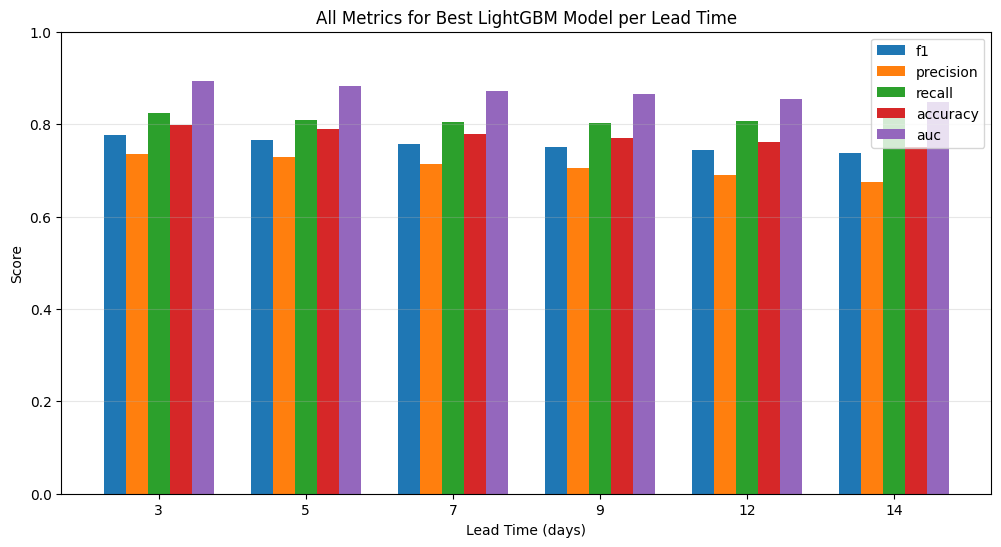

In [ ]:
best_lgbm_per_lead = results_df.loc[
    results_df.groupby('lead_time')['f1'].idxmax()
].reset_index(drop=True)

print(best_lgbm_per_lead[['lead_time', 'model', 'f1', 'precision', 'recall', 'accuracy', 'auc']],'\n\n')


metrics = ['f1', 'precision', 'recall', 'accuracy', 'auc']
lead_times = best_lgbm_per_lead['lead_time']

x = np.arange(len(lead_times))  # positions
width = 0.15  # bar width

fig, ax = plt.subplots(figsize=(12,6))

for i, metric in enumerate(metrics):
    ax.bar(
        x + i*width,
        best_lgbm_per_lead[metric],
        width=width,
        label=metric
    )

ax.set_xlabel('Lead Time (days)')
ax.set_ylabel('Score')
ax.set_title('All Metrics for Best LightGBM Model per Lead Time')
ax.set_xticks(x + width*2)
ax.set_xticklabels(lead_times)
ax.set_ylim(0,1)
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.show()